# Eksperimen Komparasi Modular Optimizer pada PySNE

Notebook ini mendemonstrasikan **modularisasi optimizer** pada library PySNE:
1. **Cara Penggunaan**: Memanggil berbagai optimizer (SPO bawaan, Newton/Powell Hybrid, Levenberg-Marquardt, dan Custom Optimizer).
2. **Inspeksi Numerik**: Memeriksa koordinat akar dan residual persamaan $\max_i |f_i(\mathbf{x}^*)|$.
3. **Eksperimen Komparasi**: Membandingkan kelengkapan akar (*completeness*), waktu komputasi (*runtime*), dan presisi residual.
4. **Visualisasi**: Plot perbandingan waktu komputasi (skala log) dan visualisasi kontur sebaran akar.


## 1. Setup Lingkungan & Import Library

Kita mengimpor pustaka komputasi numerik standar (`numpy`, `matplotlib`, `time`) serta solver PySNE.


In [1]:
# Import library standar
import sys
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Pastikan path root repository pysne masuk ke sys.path secara portabel
current_dir = Path.cwd()
# Cari direktori root repository (yang memuat folder pysne/)
repo_root = current_dir
while repo_root.parent != repo_root:
    if (repo_root / "pysne").is_dir() and (repo_root / "pyproject.toml").is_file():
        break
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Import modul solver dan optimizer PySNE
from pysne import solve_system
from pysne.optimizers import ScipyRootOptimizer, SPOOptimizer
from pysne.problems.benchmarks_sne import get_problem_set

# Set random seed untuk reproduktibilitas sebaran titik Sobol
np.random.seed(42)

print(f"Repository root: {repo_root}")
print("Modul PySNE berhasil diimpor!")


Repository root: /Users/macintoshhd/Documents/School/tugas-akhir-v1.0/previous-work/pysne
Modul PySNE berhasil diimpor!


## 2. Cara Penggunaan Berbagai Optimizer pada PySNE

Kita gunakan **Problem 1 Benchmark System**:
$$
\begin{aligned}
f_1(x_1, x_2) &= e^{x_1 - x_2} - \sin(x_1 + x_2) = 0 \\
f_2(x_1, x_2) &= x_1^2 x_2^2 - \cos(x_1 + x_2) = 0
\end{aligned}
$$
pada domain $D = [-10, 10] \times [-10, 10]$ dengan target $6$ akar riil unik.


In [2]:
# Inisialisasi masalah benchmark 1
prob1 = get_problem_set()[1]()
domain, params = prob1.get_info()
expected_n = params.get('expected_roots', 6)

# -------------------------------------------------------------------------
# OPSI 1: Spiral Optimization (Bawaan / 'spo')
# -------------------------------------------------------------------------
t0 = time.time()
res_spo = solve_system(prob1, params, optimizer="spo", verbose=False)
t_spo = time.time() - t0

# -------------------------------------------------------------------------
# OPSI 2: Newton-Raphson / Powell Hybrid ('newton' / 'hybr')
# -------------------------------------------------------------------------
t0 = time.time()
res_newton = solve_system(prob1, params, optimizer="newton", verbose=False)
t_newton = time.time() - t0

# -------------------------------------------------------------------------
# OPSI 3: Levenberg-Marquardt (ScipyRootOptimizer(method='lm'))
# -------------------------------------------------------------------------
t0 = time.time()
res_lm = solve_system(prob1, params, optimizer=ScipyRootOptimizer(method="lm"), verbose=False)
t_lm = time.time() - t0

# -------------------------------------------------------------------------
# OPSI 4: Custom Optimizer (Fungsi Buatan Pengguna)
# -------------------------------------------------------------------------
def custom_centroid_optimizer(problem, cluster, cluster_domain, params):
    # Contoh optimizer sederhana: mengambil tebakan awal dari pusat klaster
    return cluster.center.copy()

res_custom = solve_system(prob1, params, optimizer=custom_centroid_optimizer, verbose=False)

# Tampilkan hasil ringkasan
print(f"=== Hasil Pengujian Problem 1 (Target: {expected_n} akar) ===")
print(f"[1] SPO                 : {len(res_spo['roots'])} akar ditemukan | Waktu: {t_spo:.3f} detik")
print(f"[2] Newton (hybr)       : {len(res_newton['roots'])} akar ditemukan | Waktu: {t_newton:.3f} detik")
print(f"[3] Levenberg-Marquardt : {len(res_lm['roots'])} akar ditemukan | Waktu: {t_lm:.3f} detik")
print(f"[4] Custom Optimizer    : {len(res_custom['roots'])} akar ditemukan")


/Users/macintoshhd/Documents/School/tugas-akhir-v1.0/previous-work/pysne/pysne/initialization/sampling.py:36: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  unit_points = sampler.random(n=num_points)


=== Hasil Pengujian Problem 1 (Target: 6 akar) ===
[1] SPO                 : 6 akar ditemukan | Waktu: 3.057 detik
[2] Newton (hybr)       : 6 akar ditemukan | Waktu: 0.026 detik
[3] Levenberg-Marquardt : 6 akar ditemukan | Waktu: 0.031 detik
[4] Custom Optimizer    : 0 akar ditemukan


## 3. Inspeksi Koordinat Akar dan Galat Residual

Untuk memastikan apakah solusi yang ditemukan valid dan akurat, kita hitung residual persamaan maksimumnya:
$$
\text{Residual Maksimum} = \max_{i=1, \dots, m} |f_i(\mathbf{x}^*)| 
$$


In [3]:
def max_residual(prob, x):
    # Hitung nilai absolut residual untuk seluruh persamaan fi(x)
    return max(abs(eq(x)) for eq in prob.equations)

print("Akar-akar yang Ditemukan oleh Newton (hybr):")
print("-" * 60)
for i, r in enumerate(res_newton['roots'], 1):
    res = max_residual(prob1, r)
    print(f"  Akar {i}: x1 = {r[0]:10.6f},  x2 = {r[1]:10.6f} | Max Residual = {res:.2e}")

print("\nAkar-akar yang Ditemukan oleh SPO:")
print("-" * 60)
for i, r in enumerate(res_spo['roots'], 1):
    res = max_residual(prob1, r)
    print(f"  Akar {i}: x1 = {r[0]:10.6f},  x2 = {r[1]:10.6f} | Max Residual = {res:.2e}")


Akar-akar yang Ditemukan oleh Newton (hybr):
------------------------------------------------------------
  Akar 1: x1 =  -0.932122,  x2 =   1.067874 | Max Residual = 1.89e-15
  Akar 2: x1 =   0.667121,  x2 =   0.690103 | Max Residual = 4.85e-13
  Akar 3: x1 =  -6.437163,  x2 =   0.155348 | Max Residual = 1.64e-12
  Akar 4: x1 =  -6.117113,  x2 =  -0.163476 | Max Residual = 9.32e-12
  Akar 5: x1 =   0.163333,  x2 =   6.122434 | Max Residual = 4.12e-11
  Akar 6: x1 =  -0.155283,  x2 =   6.439836 | Max Residual = 1.04e-09

Akar-akar yang Ditemukan oleh SPO:
------------------------------------------------------------
  Akar 1: x1 =  -6.117113,  x2 =  -0.163476 | Max Residual = 2.44e-08
  Akar 2: x1 =  -0.932122,  x2 =   1.067874 | Max Residual = 3.56e-08
  Akar 3: x1 =   0.667121,  x2 =   0.690103 | Max Residual = 4.91e-08
  Akar 4: x1 =  -0.155283,  x2 =   6.439836 | Max Residual = 5.22e-08
  Akar 5: x1 =   0.163333,  x2 =   6.122434 | Max Residual = 8.39e-08
  Akar 6: x1 =  -6.437163, 

## 4. Eksperimen Komparasi Sistematis (Akurasi & Runtime)

Sekarang kita uji performa perbandingan SPO, Newton, dan Levenberg-Marquardt pada beberapa masalah benchmark:
- **Problem 1**: Sistem non-linear 2D polinomial dan trigonometri (6 akar).
- **Problem 2**: Sistem non-linear 2D eksponensial transenden dengan domain luas (12 akar).

*(Catatan: Anda juga dapat menambahkan Problem 3 (6 dimensi) ke daftar di bawah. Pada Problem 3, Newton selesai dalam ~0.5 detik sedangkan SPO memakan waktu ~5 menit karena dimensi tinggi).*


In [4]:
# Daftar masalah benchmark yang akan diuji
test_problem_ids = [1, 2]

benchmark_results = []

for pid in test_problem_ids:
    problem = get_problem_set()[pid]()
    p_domain, p_params = problem.get_info()
    target_roots = p_params.get('expected_roots', '?')
    dim = problem.n_var
    
    print(f"\n>>> Menjalankan Problem {pid} (Dimensi: {dim}, Target: {target_roots} akar)...")
    
    # 1. Evaluasi SPO
    t_start = time.time()
    out_spo = solve_system(problem, p_params, optimizer="spo", verbose=False)
    dur_spo = time.time() - t_start
    n_spo = len(out_spo['roots'])
    cur_res_spo = max(max_residual(problem, r) for r in out_spo['roots']) if n_spo > 0 else np.nan
    
    # 2. Evaluasi Newton (hybr)
    t_start = time.time()
    out_newton = solve_system(problem, p_params, optimizer="newton", verbose=False)
    dur_newton = time.time() - t_start
    n_newton = len(out_newton['roots'])
    cur_res_newton = max(max_residual(problem, r) for r in out_newton['roots']) if n_newton > 0 else np.nan
    
    # 3. Evaluasi Levenberg-Marquardt
    t_start = time.time()
    out_lm = solve_system(problem, p_params, optimizer=ScipyRootOptimizer(method="lm"), verbose=False)
    dur_lm = time.time() - t_start
    n_lm = len(out_lm['roots'])
    cur_res_lm = max(max_residual(problem, r) for r in out_lm['roots']) if n_lm > 0 else np.nan
    
    benchmark_results.append({
        'id': f"Problem {pid}",
        'dim': dim,
        'target': target_roots,
        'spo_n': n_spo, 'spo_time': dur_spo, 'spo_res': cur_res_spo,
        'newton_n': n_newton, 'newton_time': dur_newton, 'newton_res': cur_res_newton,
        'lm_n': n_lm, 'lm_time': dur_lm, 'lm_res': cur_res_lm
    })

# Tampilkan tabel hasil dalam format teks rapi
print("\n" + "=" * 95)
print(f"{'Masalah':<12} | {'Dim':<4} | {'Target':<6} | {'SPO (Akar / Waktu / Res)':<25} | {'Newton (Akar / Waktu / Res)':<25} | {'LM (Waktu)':<10}")
print("=" * 95)
for row in benchmark_results:
    spo_str = f"{row['spo_n']} / {row['spo_time']:.2f}s / {row['spo_res']:.1e}"
    newton_str = f"{row['newton_n']} / {row['newton_time']:.3f}s / {row['newton_res']:.1e}"
    lm_str = f"{row['lm_time']:.3f}s"
    print(f"{row['id']:<12} | {row['dim']:<4} | {row['target']:<6} | {spo_str:<25} | {newton_str:<25} | {lm_str:<10}")
print("=" * 95)



>>> Menjalankan Problem 1 (Dimensi: 2, Target: 6 akar)...



>>> Menjalankan Problem 2 (Dimensi: 2, Target: 12 akar)...



Masalah      | Dim  | Target | SPO (Akar / Waktu / Res)  | Newton (Akar / Waktu / Res) | LM (Waktu)
Problem 1    | 2    | 6      | 6 / 4.70s / 8.4e-08       | 6 / 0.028s / 1.0e-09      | 0.032s    
Problem 2    | 2    | 12     | 12 / 26.40s / 6.3e-08     | 12 / 0.290s / 8.9e-10     | 0.279s    


## 5. Visualisasi Grafik Perbandingan & Lanskap Solusi

Kita membuat dua visualisasi:
1. **Diagram Batang Waktu Komputasi**: Menunjukkan efisiensi waktu konvergensi masing-masing metode (skala logaritmik).
2. **Peta Kontur Residual**: Memplot sebaran akar yang ditemukan di atas lanskap $\log_{10}\left(\sum |f_i|\right)$ untuk memastikan akurasi spasial solusi.


Grafik berhasil disimpan ke: /Users/macintoshhd/Documents/School/tugas-akhir-v1.0/previous-work/pysne/outputs/figures/optimizer_comparison_chart.png


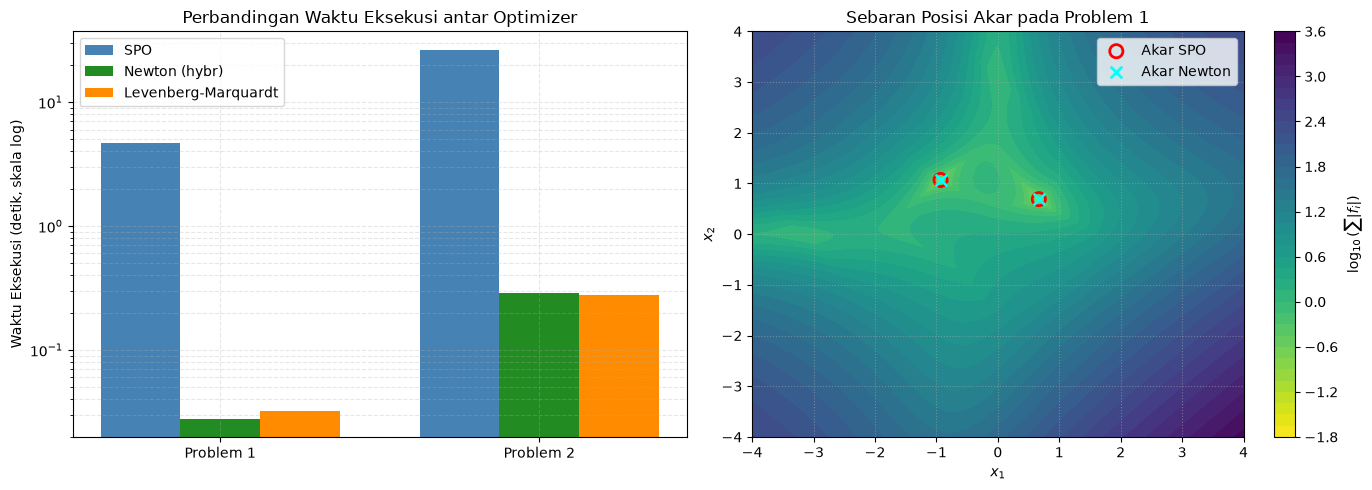

In [5]:
# Siapkan direktori output gambar sesuai panduan AGENTS.md
fig_dir = repo_root / "outputs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# -------------------------------------------------------------------------
# Subplot 1: Bar Plot Perbandingan Runtime
# -------------------------------------------------------------------------
labels = [r['id'] for r in benchmark_results]
x_pos = np.arange(len(labels))
width = 0.25

times_spo = [r['spo_time'] for r in benchmark_results]
times_newton = [r['newton_time'] for r in benchmark_results]
times_lm = [r['lm_time'] for r in benchmark_results]

ax1.bar(x_pos - width, times_spo, width, label='SPO', color='steelblue')
ax1.bar(x_pos, times_newton, width, label='Newton (hybr)', color='forestgreen')
ax1.bar(x_pos + width, times_lm, width, label='Levenberg-Marquardt', color='darkorange')

ax1.set_yscale('log')
ax1.set_ylabel('Waktu Eksekusi (detik, skala log)')
ax1.set_title('Perbandingan Waktu Eksekusi antar Optimizer')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels)
ax1.legend()
ax1.grid(True, which="both", ls="--", alpha=0.3)

# -------------------------------------------------------------------------
# Subplot 2: Kontur Residual Problem 1 dan Sebaran Akar
# -------------------------------------------------------------------------
grid_vals = np.linspace(-4, 4, 250)
X1, X2 = np.meshgrid(grid_vals, grid_vals)

F1 = np.exp(X1 - X2) - np.sin(X1 + X2)
F2 = (X1**2) * (X2**2) - np.cos(X1 + X2)
Total_Residual = np.abs(F1) + np.abs(F2)

# Plot kontur log10(residual)
contour = ax2.contourf(X1, X2, np.log10(Total_Residual + 1e-8), levels=35, cmap='viridis_r')
cbar = fig.colorbar(contour, ax=ax2)
cbar.set_label(r'$\log_{10}(\sum |f_i|)$')

# Plot akar SPO dan Newton
spo_roots = res_spo['roots']
newton_roots = res_newton['roots']

ax2.scatter(spo_roots[:, 0], spo_roots[:, 1], color='red', marker='o', s=90,
            facecolors='none', linewidths=2, label='Akar SPO')
ax2.scatter(newton_roots[:, 0], newton_roots[:, 1], color='cyan', marker='x', s=70,
            linewidths=2, label='Akar Newton')

ax2.set_xlim(-4, 4)
ax2.set_ylim(-4, 4)
ax2.set_xlabel(r'$x_1$')
ax2.set_ylabel(r'$x_2$')
ax2.set_title('Sebaran Posisi Akar pada Problem 1')
ax2.legend(loc='upper right')
ax2.grid(True, ls=':', alpha=0.5)

plt.tight_layout()

# Simpan hasil visualisasi
fig_path = fig_dir / "optimizer_comparison_chart.png"
plt.savefig(fig_path, dpi=150)
print(f"Grafik berhasil disimpan ke: {fig_path}")
plt.show()
